# D03 · Training signal is not task improvement
Compare SFT, GRPO and a continued-SFT control under matched inference budgets. Visualize reward contrast and calculate a simplified group-relative advantage.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D03", SNAPSHOT_PATH)

D03 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/rlvr/local-s41-20261026T180904Z-d20988 | recorded: 20261026T180904Z | seed: 41


## The concept
RLVR learns from executable outcome feedback. In this GRPO configuration, candidates within a prompt group receive binary public-verifier rewards. The relative advantage depends on reward differences within the group. A group where every candidate scores one has no relative reward contrast.
Best-of-N is an inference strategy: generate N candidates and choose using public checks. Hidden checks grade the chosen response afterward; they must never choose it.

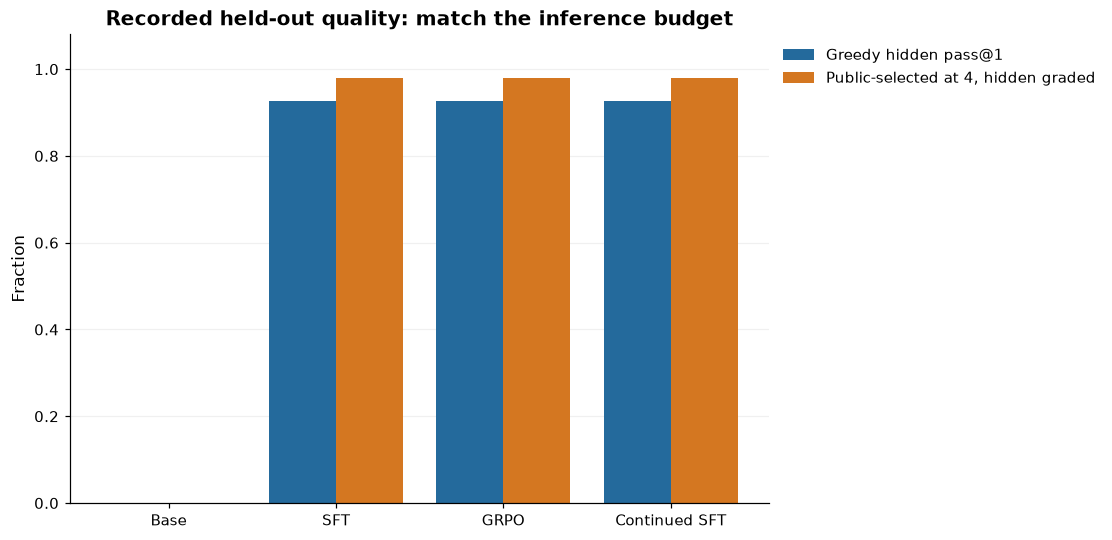

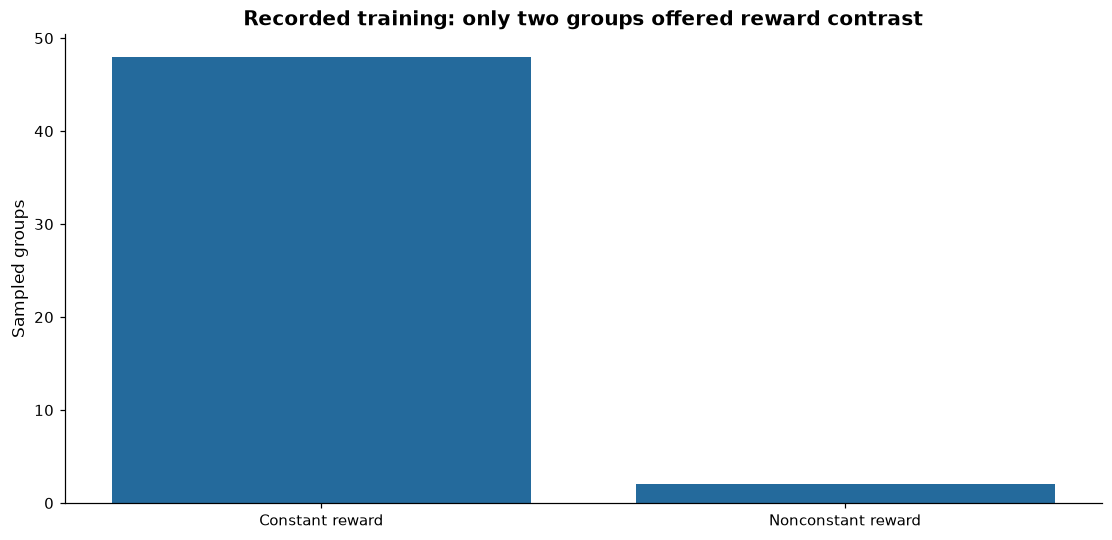

Weights changed: True | optimizer steps: 50


In [2]:
variants = ['base', 'sft', 'rlvr', 'sft_control']
grouped_bars(['Base', 'SFT', 'GRPO', 'Continued SFT'], {
    'Greedy hidden pass@1': [d['metrics'][v]['greedy_pass_at_1'] for v in variants],
    'Public-selected at 4, hidden graded': [d['metrics'][v]['verifier_selected_success_at_n'] for v in variants],
}, title='Recorded held-out quality: match the inference budget')
plt.show()
t = d['training']
fig, ax = plt.subplots(layout='constrained')
ax.bar(['Constant reward', 'Nonconstant reward'],
       [t['constant_reward_groups'], t['nonconstant_reward_groups']])
ax.set(title='Recorded training: only two groups offered reward contrast', ylabel='Sampled groups')
plt.show()
print('Weights changed:', t['parameters_changed'], '| optimizer steps:', t['optimizer_steps'])

### Change the reward group
This is a **teaching calculation**, not a replay of the trainer loss. Center rewards and divide by their population standard deviation plus epsilon. Exact trainer scaling and other loss terms can differ. Compare `[1,1,1,1]`, `[0,0,0,0]` and `[0,1,1,1]`.

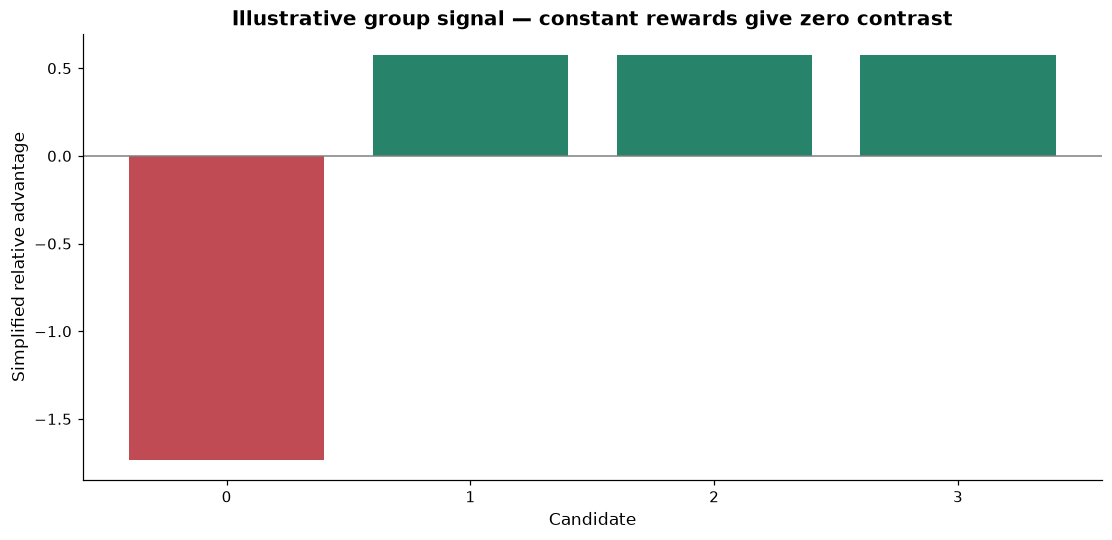

In [3]:
rewards = np.array([0, 1, 1, 1], dtype=float)
advantages = (rewards - rewards.mean()) / (rewards.std() + 1e-8)
fig, ax = plt.subplots(layout='constrained')
ax.bar(np.arange(len(rewards)), advantages, color=['#c04b55' if a < 0 else '#28836b' for a in advantages])
ax.axhline(0, color='gray', lw=1)
ax.set(xticks=np.arange(len(rewards)), xlabel='Candidate', ylabel='Simplified relative advantage',
       title='Illustrative group signal — constant rewards give zero contrast')
plt.show()

**Interpretation check:** why is 94/96 selected-at-four success not evidence that RL helped? The SFT baseline already reaches it with the same selection budget. All SFT-derived variants have 89/96 greedy success. The 48 constant groups suggest a signal limitation but do not isolate every cause of the null result. The control matches training wall time, not tokens or FLOPs.

## What you learned and when to use it
Use executable rewards when the verifier is meaningful and supplies informative contrast. Compare continued SFT and inference-time verification first. More optimizer steps are not evidence of useful behavior change; this recorded run favors the simpler SFT model.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d03--learn-from-verifiable-rewards).
**Train or run the actual model:** follow the [D03 tutorial](../docs/RLVR_DEMO.md). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)